# 03 · Modelos clásicos de machine learning (Módulo 3)
**Sistema de apoyo para detección de tumores cerebrales en resonancia magnética**

Problema binario: **tumor (1)** contra **sin tumor (0)**. El error más costoso es el **falso negativo**, así que la métrica principal es la **sensibilidad**.

| # | Modelo | Rasgos | Idea |
|---|---|---|---|
| 1 | Regresión logística | Básicos (brillo, contraste, histograma) | **La solución más simple.** Mide cuánto se puede acertar sin mirar la anatomía |
| 2 | Regresión logística | MobileNetV2 (1,280) | Frontera lineal sobre rasgos de una red preentrenada |
| 3 | Random Forest | MobileNetV2 | Muchos árboles que votan |
| 4 | SVM con núcleo RBF | MobileNetV2 | Frontera curva; con probabilidades |

**Reglas de la evaluación**
- Validación cruzada estratificada de **5 pliegues por grupos de similitud** (`StratifiedGroupKFold(5, shuffle=True, random_state=42)`, estratificada por las 4 clases), **solo sobre el entrenamiento**. Los pliegues se calcularon en el notebook 01 y están en la columna `pliegue` del manifiesto: todos los modelos, incluida la red, usan exactamente los mismos. Las imágenes muy parecidas (mismo grupo) caen siempre en el mismo pliegue.
- Cada modelo es un `Pipeline` con escalado: el escalado se ajusta solo con los datos de entrenamiento de cada pliegue (sin fuga de información).
- `class_weight="balanced"` por el desbalance (hay muchas más imágenes con tumor que sin tumor; la proporción exacta se imprime en la sección 1).
- El **umbral** de cada modelo se elige con las predicciones **fuera de pliegue**: es el punto medio entre la probabilidad límite que alcanza sensibilidad ≥ 0.98 y la siguiente inferior.
- El **conjunto de prueba se evalúa una sola vez, al final**, con el modelo reentrenado en todo el entrenamiento y el umbral ya fijado. La prueba no participa en ninguna elección.

In [1]:
import os
import sys
import time
from pathlib import Path

RAIZ = Path.cwd().resolve()
while not (RAIZ / "app" / "backend" / "ml").is_dir():
    if RAIZ.parent == RAIZ:
        raise RuntimeError("No se encontró la raíz del proyecto.")
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))

import json
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve
from app.backend.ml.entrenar import pliegues_estratificados
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

from app.backend.ml import config, rasgos
from app.backend.ml.metricas import elegir_umbral, metricas_binarias, metricas_por_pliegue, wilson

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
config.fijar_semillas()
FIGURAS = config.RESULTADOS / "figuras"
FIGURAS.mkdir(parents=True, exist_ok=True)
CARPETA_MODELOS = config.RESULTADOS / "modelos_clasicos"
CARPETA_MODELOS.mkdir(parents=True, exist_ok=True)
OBJETIVO = config.SENSIBILIDAD_OBJETIVO
INICIO = time.time()
print("Versiones:", config.versiones())

Versiones: {'python': '3.12.10', 'numpy': '2.5.5', 'sklearn': '1.9.1', 'tensorflow': '2.21.0', 'keras': '3.15.1', 'opencv': '5.1.0', 'pandas': '3.1.1'}


## 1. Datos
Se leen el manifiesto y los rasgos guardados por el notebook 02 (mismo orden).

In [2]:
man = pd.read_csv(config.MANIFIESTO)
FIRMA = rasgos.firma_cache(man)
with np.load(config.RASGOS / "rasgos_mobilenet.npz", allow_pickle=False) as d:
    X_mob, rutas_mob = d["X"], d["rutas"]
    assert str(d["firma"]) == FIRMA, "Los rasgos guardados son de otro manifiesto o preprocesamiento: ejecute de nuevo el notebook 02."
with np.load(config.RASGOS / "rasgos_basicos.npz", allow_pickle=False) as d:
    X_bas, rutas_bas = d["X"], d["rutas"]
assert (rutas_mob == man.ruta.to_numpy()).all() and (rutas_bas == man.ruta.to_numpy()).all(), "Los rasgos no corresponden al manifiesto: ejecute de nuevo el notebook 02."

ent = (man.particion == "entrenamiento").to_numpy()
pru = (man.particion == "prueba").to_numpy()
man_ent, man_pru = man[ent].reset_index(drop=True), man[pru].reset_index(drop=True)
y_ent, y_pru = man_ent.es_tumor.to_numpy(), man_pru.es_tumor.to_numpy()
RASGOS = {"basicos": (X_bas[ent], X_bas[pru]), "mobilenet": (X_mob[ent], X_mob[pru])}
print(f"Entrenamiento: {len(y_ent):,} ({y_ent.mean():.1%} con tumor) · Prueba: {len(y_pru):,} ({y_pru.mean():.1%} con tumor)")

# Pliegues: estratificados por las 4 clases (eso también estratifica tumor / sin tumor).
pliegue_de = man_ent.pliegue.to_numpy()
PLIEGUES = [(np.flatnonzero(pliegue_de != k), np.flatnonzero(pliegue_de == k)) for k in range(1, config.N_PLIEGUES + 1)]
# Comprobación: son los pliegues por grupos que da el paquete compartido, y ningún grupo está repartido
recalculados = pliegues_estratificados(man_ent.clase.to_numpy(), config.N_PLIEGUES, config.SEMILLA, man_ent.grupo_similitud.to_numpy())
assert all((a[1] == b[1]).all() for a, b in zip(PLIEGUES, recalculados)), "Los pliegues del manifiesto no coinciden con los recalculados."
assert man_ent.groupby("grupo_similitud").pliegue.nunique().max() == 1
assert not set(man_ent.grupo_similitud) & set(man_pru.grupo_similitud), "Hay grupos de similitud repartidos entre entrenamiento y prueba."
print(f"Grupos de similitud en entrenamiento: {man_ent.grupo_similitud.nunique():,} · ninguno repartido entre pliegues ni compartido con la prueba")
print(f"Imágenes 'sin tumor' en prueba: {int((y_pru == 0).sum())} (la especificidad de prueba se mide con esas pocas imágenes: su intervalo de confianza es ancho)")
display(pd.crosstab(pd.Series(pliegue_de, name="pliegue"), man_ent.clase))

Entrenamiento: 2,880 (89.8% con tumor) · Prueba: 720 (89.9% con tumor)


Grupos de similitud en entrenamiento: 2,608 · ninguno repartido entre pliegues ni compartido con la prueba
Imágenes 'sin tumor' en prueba: 73 (la especificidad de prueba se mide con esas pocas imágenes: su intervalo de confianza es ancho)


clase,glioma,meningioma,notumor,pituitary
pliegue,,,,
1,233,131,59,153
2,233,131,59,153
3,234,131,58,153
4,233,131,59,153
5,233,131,59,153


## 2. Modelos

In [3]:
def tuberia(modelo):
    return Pipeline([("escala", StandardScaler()), ("modelo", modelo)])

MODELOS = {
    "Logística (rasgos básicos)": {"archivo": "logistica_basica", "rasgos": "basicos",
        "tuberia": tuberia(LogisticRegression(max_iter=5000, C=1.0, class_weight="balanced", random_state=config.SEMILLA))},
    "Logística (MobileNetV2)": {"archivo": "logistica_mobilenet", "rasgos": "mobilenet",
        "tuberia": tuberia(LogisticRegression(max_iter=5000, C=1.0, class_weight="balanced", random_state=config.SEMILLA))},
    "Random Forest (MobileNetV2)": {"archivo": "random_forest", "rasgos": "mobilenet",
        "tuberia": tuberia(RandomForestClassifier(n_estimators=300, class_weight="balanced", n_jobs=-1, random_state=config.SEMILLA))},
    "SVM RBF (MobileNetV2)": {"archivo": "svm_rbf", "rasgos": "mobilenet",
        "tuberia": tuberia(SVC(kernel="rbf", C=10, gamma="scale", class_weight="balanced", probability=True, random_state=config.SEMILLA))},
}
for nombre, m in MODELOS.items():
    print(f"{nombre}: {m['tuberia'].named_steps['modelo']}")

Logística (rasgos básicos): LogisticRegression(class_weight='balanced', max_iter=5000, random_state=42)
Logística (MobileNetV2): LogisticRegression(class_weight='balanced', max_iter=5000, random_state=42)
Random Forest (MobileNetV2): RandomForestClassifier(class_weight='balanced', n_estimators=300, n_jobs=-1,
                       random_state=42)
SVM RBF (MobileNetV2): SVC(C=10, class_weight='balanced', probability=True, random_state=42)


Los hiperparámetros son valores fijos razonables (no se buscaron con la prueba ni con una búsqueda en malla): el objetivo es comparar familias de modelos en igualdad de condiciones.

## 3. Validación cruzada
Para cada modelo y cada pliegue: se entrena con 4 partes y se predice la parte restante. Así cada imagen de entrenamiento recibe una probabilidad de un modelo que **no la vio** (predicción fuera de pliegue).

In [4]:
prob_oof, segundos = {}, {}
for nombre, m in MODELOS.items():
    X = RASGOS[m["rasgos"]][0]
    t0 = time.time()
    p = np.full(len(y_ent), np.nan)
    for i_tr, i_va in PLIEGUES:
        modelo = clone(m["tuberia"]).fit(X[i_tr], y_ent[i_tr])
        p[i_va] = modelo.predict_proba(X[i_va])[:, 1]
    assert not np.isnan(p).any()
    prob_oof[nombre], segundos[nombre] = p, time.time() - t0
    print(f"{nombre:30s} listo en {segundos[nombre]:6.1f} s · AUC fuera de pliegue = {metricas_binarias(y_ent, p)['auc']:.4f}")

Logística (rasgos básicos)     listo en    0.1 s · AUC fuera de pliegue = 0.9020


Logística (MobileNetV2)        listo en    0.4 s · AUC fuera de pliegue = 0.9863


Random Forest (MobileNetV2)    listo en    6.7 s · AUC fuera de pliegue = 0.9854


SVM RBF (MobileNetV2)          listo en   21.2 s · AUC fuera de pliegue = 0.9911


## 4. Umbral de decisión
Por defecto un modelo dice "tumor" cuando la probabilidad es ≥ 0.5. Aquí el umbral se baja o se sube para que la **sensibilidad sea al menos 0.98**: se toma el umbral más alto que lo cumple sobre las predicciones fuera de pliegue (así se pierde la menor especificidad posible).

**Nota honesta:** como el umbral se elige con todas las predicciones fuera de pliegue juntas, la sensibilidad de la validación cruzada queda en 0.98 por construcción. Lo que distingue a los modelos en la validación cruzada es la **especificidad** que conservan a esa sensibilidad y el **AUC** (que no depende del umbral). La medición independiente es la del conjunto de prueba, al final.

In [5]:
METRICAS = ["sensibilidad", "especificidad", "precision", "f1", "auc", "exactitud"]
umbrales, filas_pliegue, filas_resumen, filas_oof = {}, [], [], []
for nombre in MODELOS:
    p = prob_oof[nombre]
    u = elegir_umbral(y_ent, p, OBJETIVO)
    umbrales[nombre] = u
    por_pliegue = pd.DataFrame(metricas_por_pliegue(y_ent, p, pliegue_de, u))
    en_05 = pd.DataFrame(metricas_por_pliegue(y_ent, p, pliegue_de, 0.5))
    por_pliegue["sensibilidad_umbral_05"], por_pliegue["especificidad_umbral_05"] = en_05.sensibilidad, en_05.especificidad
    por_pliegue.insert(0, "modelo", nombre)
    filas_pliegue.append(por_pliegue)
    total = metricas_binarias(y_ent, p, u)
    fila = {"modelo": nombre, "umbral": u}
    for met in METRICAS:
        fila[f"{met}_media"], fila[f"{met}_std"] = por_pliegue[met].mean(), por_pliegue[met].std(ddof=1)
    fila.update({"sensibilidad_oof": total["sensibilidad"], "especificidad_oof": total["especificidad"], "auc_oof": total["auc"],
                 "vp": total["vp"], "vn": total["vn"], "fp": total["fp"], "fn": total["fn"],
                 "segundos_cv": segundos[nombre], "nota": "5 pliegues; modelo completo en cada pliegue"})
    filas_resumen.append(fila)
    filas_oof.append(pd.DataFrame({"ruta": man_ent.ruta, "modelo": nombre, "pliegue": pliegue_de, "clase": man_ent.clase,
                                   "es_tumor": y_ent, "probabilidad_tumor": p, "umbral": u, "prediccion": (p >= u).astype(int)}))

cv_pliegues = pd.concat(filas_pliegue, ignore_index=True)
cv_resumen = pd.DataFrame(filas_resumen)
pred_oof = pd.concat(filas_oof, ignore_index=True)
cv_pliegues.to_csv(config.RESULTADOS / "cv_pliegues.csv", index=False, encoding="utf-8")
cv_resumen.to_csv(config.RESULTADOS / "cv_resumen.csv", index=False, encoding="utf-8")
pred_oof.to_csv(config.RESULTADOS / "predicciones_oof.csv", index=False, encoding="utf-8")

print("Métricas por pliegue (al umbral elegido):")
display(cv_pliegues.round(4))

def media_std(tabla, metricas=METRICAS[:5]):
    vista = tabla[["modelo", "umbral"]].copy()
    vista["umbral"] = vista.umbral.round(4)
    for met in metricas:
        vista[met] = [f"{a:.4f} ± {b:.4f}" for a, b in zip(tabla[f"{met}_media"], tabla[f"{met}_std"])]
    return vista

print("Resumen: media ± desviación estándar de los 5 pliegues")
display(media_std(cv_resumen))
display(cv_resumen[["modelo", "sensibilidad_oof", "especificidad_oof", "auc_oof", "vp", "vn", "fp", "fn", "segundos_cv"]].round(4))

Métricas por pliegue (al umbral elegido):


,modelo,pliegue,umbral,vp,vn,fp,fn,sensibilidad,especificidad,precision,f1,exactitud,auc,sensibilidad_umbral_05,especificidad_umbral_05
0,Logística (rasgos básicos),1,0.0225,505,12,47,12,0.9768,0.2034,0.9149,0.9448,0.8976,0.9310,0.9246,0.8305
1,Logística (rasgos básicos),2,0.0225,507,20,39,10,0.9807,0.3390,0.9286,0.9539,0.9149,0.8338,0.8975,0.7627
2,Logística (rasgos básicos),3,0.0225,506,19,39,12,0.9768,0.3276,0.9284,0.9520,0.9115,0.9138,0.9112,0.8276
3,Logística (rasgos básicos),4,0.0225,509,16,43,8,0.9845,0.2712,0.9221,0.9523,0.9115,0.9542,0.9362,0.8136
4,Logística (rasgos básicos),5,0.0225,508,12,47,9,0.9826,0.2034,0.9153,0.9478,0.9028,0.8874,0.9246,0.7627
5,Logística (MobileNetV2),1,0.6276,511,52,7,6,0.9884,0.8814,0.9865,0.9874,0.9774,0.9900,0.9903,0.8475
6,Logística (MobileNetV2),2,0.6276,504,52,7,13,0.9749,0.8814,0.9863,0.9805,0.9653,0.9664,0.9807,0.8644
7,Logística (MobileNetV2),3,0.6276,503,51,7,15,0.9710,0.8793,0.9863,0.9786,0.9618,0.9927,0.9730,0.8793
8,Logística (MobileNetV2),4,0.6276,506,54,5,11,0.9787,0.9153,0.9902,0.9844,0.9722,0.9928,0.9826,0.8644
9,Logística (MobileNetV2),5,0.6276,511,51,8,6,0.9884,0.8644,0.9846,0.9865,0.9757,0.9919,0.9903,0.7966


Resumen: media ± desviación estándar de los 5 pliegues


,modelo,umbral,sensibilidad,especificidad,precision,f1,auc
0,Logística (rasgos básicos),0.0225,0.9803 ± 0.0034,0.2689 ± 0.0651,0.9219 ± 0.0067,0.9502 ± 0.0038,0.9040 ± 0.0462
1,Logística (MobileNetV2),0.6276,0.9803 ± 0.0079,0.8843 ± 0.0187,0.9868 ± 0.0021,0.9835 ± 0.0038,0.9868 ± 0.0115
2,Random Forest (MobileNetV2),0.6367,0.9803 ± 0.0060,0.7822 ± 0.0359,0.9754 ± 0.0037,0.9778 ± 0.0016,0.9855 ± 0.0057
3,SVM RBF (MobileNetV2),0.7493,0.9803 ± 0.0088,0.9150 ± 0.0205,0.9902 ± 0.0024,0.9852 ± 0.0047,0.9913 ± 0.0033


,modelo,sensibilidad_oof,especificidad_oof,auc_oof,vp,vn,fp,fn,segundos_cv
0,Logística (rasgos básicos),0.9803,0.2687,0.9020,2535,79,215,51,0.0786
1,Logística (MobileNetV2),0.9803,0.8844,0.9863,2535,260,34,51,0.4262
2,Random Forest (MobileNetV2),0.9803,0.7823,0.9854,2535,230,64,51,6.7044
3,SVM RBF (MobileNetV2),0.9803,0.9150,0.9911,2535,269,25,51,21.2307


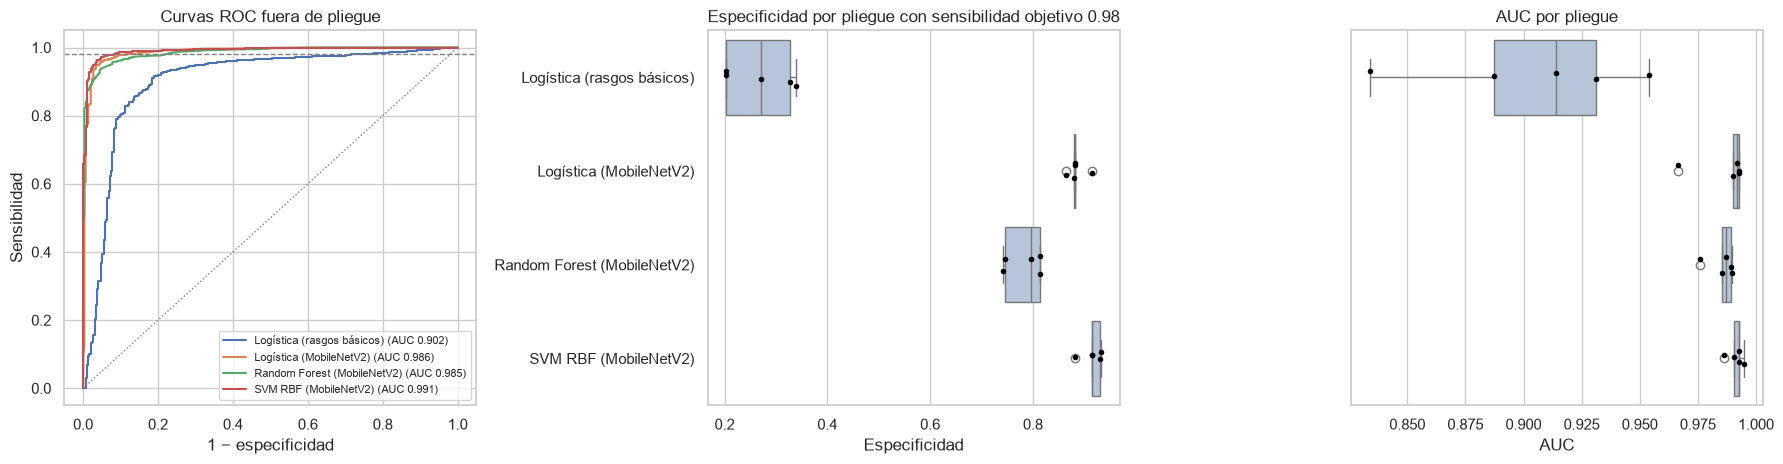

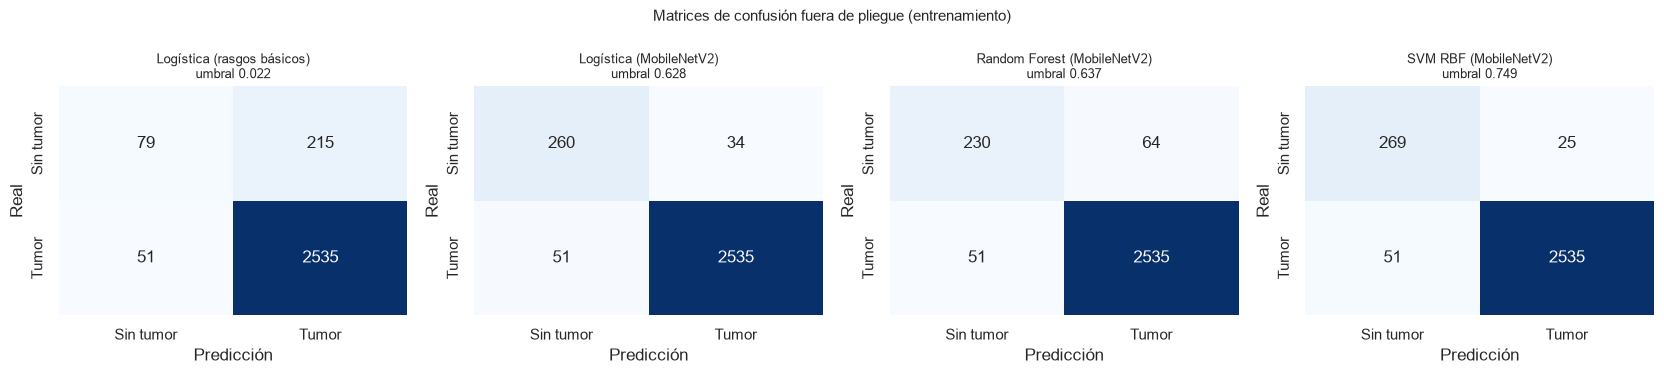

In [6]:
fig, axs = plt.subplots(1, 3, figsize=(18, 4.8))
for nombre in MODELOS:
    fpr, tpr, _ = roc_curve(y_ent, prob_oof[nombre])
    auc = cv_resumen.set_index("modelo").loc[nombre, "auc_oof"]
    axs[0].plot(fpr, tpr, label=f"{nombre} (AUC {auc:.3f})")
axs[0].axhline(OBJETIVO, ls="--", color="gray", lw=1)
axs[0].plot([0, 1], [0, 1], ls=":", color="gray", lw=1)
axs[0].set_xlabel("1 − especificidad"); axs[0].set_ylabel("Sensibilidad"); axs[0].set_title("Curvas ROC fuera de pliegue"); axs[0].legend(fontsize=8)
largo = cv_pliegues.melt(id_vars=["modelo", "pliegue"], value_vars=["especificidad"], var_name="metrica", value_name="valor")
sns.boxplot(data=largo, y="modelo", x="valor", ax=axs[1], color="lightsteelblue"); sns.stripplot(data=largo, y="modelo", x="valor", ax=axs[1], color="black", size=4)
axs[1].set_title(f"Especificidad por pliegue con sensibilidad objetivo {OBJETIVO}"); axs[1].set_ylabel(""); axs[1].set_xlabel("Especificidad")
largo = cv_pliegues.melt(id_vars=["modelo", "pliegue"], value_vars=["auc"], value_name="valor")
sns.boxplot(data=largo, y="modelo", x="valor", ax=axs[2], color="lightsteelblue"); sns.stripplot(data=largo, y="modelo", x="valor", ax=axs[2], color="black", size=4)
axs[2].set_title("AUC por pliegue"); axs[2].set_ylabel(""); axs[2].set_xlabel("AUC"); axs[2].set_yticklabels([])
plt.tight_layout(); plt.savefig(FIGURAS / "ml_01_validacion_cruzada.png", dpi=130); plt.show()

fig, axs = plt.subplots(1, len(MODELOS), figsize=(4.2 * len(MODELOS), 3.8))
for ax, nombre in zip(axs, MODELOS):
    r = cv_resumen.set_index("modelo").loc[nombre]
    cm = np.array([[r.vn, r.fp], [r.fn, r.vp]], dtype=int)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax, xticklabels=["Sin tumor", "Tumor"], yticklabels=["Sin tumor", "Tumor"])
    ax.set_title(f"{nombre}\numbral {umbrales[nombre]:.3f}", fontsize=9); ax.set_xlabel("Predicción"); ax.set_ylabel("Real")
fig.suptitle("Matrices de confusión fuera de pliegue (entrenamiento)", fontsize=11)
plt.tight_layout(); plt.savefig(FIGURAS / "ml_02_confusion_cv.png", dpi=130); plt.show()

### Mejor modelo clásico (decidido con la validación cruzada)
Criterio: la mayor **especificidad fuera de pliegue** al umbral que da sensibilidad ≥ 0.98; si hay empate, el mayor AUC. Esta elección se hace **antes** de ver la prueba.

In [7]:
orden_cv = cv_resumen.sort_values(["especificidad_oof", "auc_oof"], ascending=False).reset_index(drop=True)
MEJOR_CLASICO = orden_cv.modelo[0]
print("Mejor modelo clásico según la validación cruzada:", MEJOR_CLASICO)
display(orden_cv[["modelo", "umbral", "sensibilidad_oof", "especificidad_oof", "auc_oof"]].round(4))

Mejor modelo clásico según la validación cruzada: SVM RBF (MobileNetV2)


,modelo,umbral,sensibilidad_oof,especificidad_oof,auc_oof
0,SVM RBF (MobileNetV2),0.7493,0.9803,0.9150,0.9911
1,Logística (MobileNetV2),0.6276,0.9803,0.8844,0.9863
2,Random Forest (MobileNetV2),0.6367,0.9803,0.7823,0.9854
3,Logística (rasgos básicos),0.0225,0.9803,0.2687,0.9020


## 5. Evaluación final en el conjunto de prueba (una sola vez)
Cada modelo se reentrena con **todo** el entrenamiento y se aplica a la prueba con el umbral que ya quedó fijado arriba. Se agregan los intervalos de confianza de Wilson al 95 % para la sensibilidad y la especificidad.

,modelo,umbral,sensibilidad,especificidad,precision,f1,auc,exactitud,vp,vn,fp,fn
0,Logística (rasgos básicos),0.0225,0.9768,0.3014,0.9253,0.9504,0.9389,0.9083,632,22,51,15
1,Logística (MobileNetV2),0.6276,0.9784,0.8630,0.9844,0.9814,0.9813,0.9667,633,63,10,14
2,Random Forest (MobileNetV2),0.6367,0.9830,0.7945,0.9770,0.9800,0.9870,0.9639,636,58,15,11
3,SVM RBF (MobileNetV2),0.7493,0.9784,0.8630,0.9844,0.9814,0.9782,0.9667,633,63,10,14


,modelo,sensibilidad,sensibilidad_ic95_inferior,sensibilidad_ic95_superior,especificidad,especificidad_ic95_inferior,especificidad_ic95_superior
0,Logística (rasgos básicos),0.9768,0.9621,0.9859,0.3014,0.2082,0.4144
1,Logística (MobileNetV2),0.9784,0.9640,0.9871,0.8630,0.7659,0.9239
2,Random Forest (MobileNetV2),0.9830,0.9698,0.9905,0.7945,0.6883,0.8713
3,SVM RBF (MobileNetV2),0.9784,0.9640,0.9871,0.8630,0.7659,0.9239


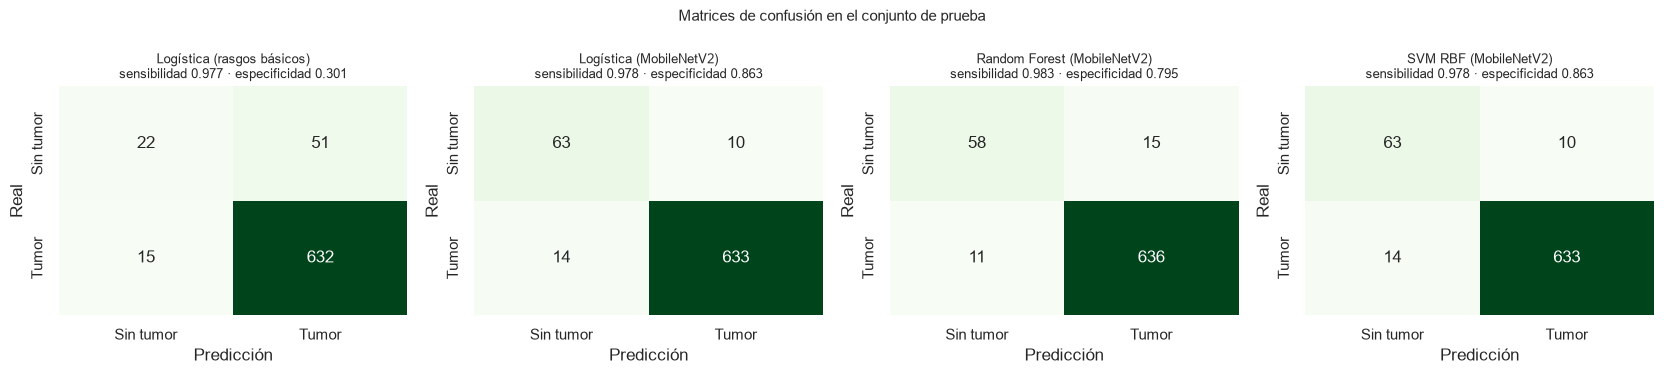

In [8]:
filas_prueba, filas_pred = [], []
for nombre, m in MODELOS.items():
    X_tr, X_te = RASGOS[m["rasgos"]]
    t0 = time.time()
    modelo = clone(m["tuberia"]).fit(X_tr, y_ent)
    joblib.dump(modelo, CARPETA_MODELOS / f"{m['archivo']}.joblib")
    p = modelo.predict_proba(X_te)[:, 1]
    u = umbrales[nombre]
    r = metricas_binarias(y_pru, p, u)
    s_li, s_ls = wilson(r["vp"], r["vp"] + r["fn"])
    e_li, e_ls = wilson(r["vn"], r["vn"] + r["fp"])
    filas_prueba.append({"modelo": nombre, "umbral": u, "n": len(y_pru), **r,
                         "sensibilidad_ic95_inferior": s_li, "sensibilidad_ic95_superior": s_ls,
                         "especificidad_ic95_inferior": e_li, "especificidad_ic95_superior": e_ls,
                         "segundos_entrenamiento": time.time() - t0})
    filas_pred.append(pd.DataFrame({"ruta": man_pru.ruta, "modelo": nombre, "clase": man_pru.clase, "es_tumor": y_pru,
                                    "probabilidad_tumor": p, "umbral": u, "prediccion": (p >= u).astype(int),
                                    "tipo_probable": "", "probabilidad_tipo": np.nan}))

prueba_resumen = pd.DataFrame(filas_prueba)
pred_prueba = pd.concat(filas_pred, ignore_index=True)
prueba_resumen.to_csv(config.RESULTADOS / "prueba_resumen.csv", index=False, encoding="utf-8")
pred_prueba.to_csv(config.RESULTADOS / "predicciones_prueba.csv", index=False, encoding="utf-8")
info_clasicos = {nombre: {"archivo": f"{m['archivo']}.joblib", "rasgos": m["rasgos"], "umbral": umbrales[nombre]} for nombre, m in MODELOS.items()}
info_clasicos["_mejor_por_validacion_cruzada"] = MEJOR_CLASICO
(CARPETA_MODELOS / "info.json").write_text(json.dumps(info_clasicos, ensure_ascii=False, indent=2), encoding="utf-8")

display(prueba_resumen[["modelo", "umbral", "sensibilidad", "especificidad", "precision", "f1", "auc", "exactitud", "vp", "vn", "fp", "fn"]].round(4))
display(prueba_resumen[["modelo", "sensibilidad", "sensibilidad_ic95_inferior", "sensibilidad_ic95_superior",
                        "especificidad", "especificidad_ic95_inferior", "especificidad_ic95_superior"]].round(4))

fig, axs = plt.subplots(1, len(MODELOS), figsize=(4.2 * len(MODELOS), 3.8))
for ax, r in zip(axs, prueba_resumen.itertuples()):
    cm = np.array([[r.vn, r.fp], [r.fn, r.vp]], dtype=int)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", cbar=False, ax=ax, xticklabels=["Sin tumor", "Tumor"], yticklabels=["Sin tumor", "Tumor"])
    ax.set_title(f"{r.modelo}\nsensibilidad {r.sensibilidad:.3f} · especificidad {r.especificidad:.3f}", fontsize=9); ax.set_xlabel("Predicción"); ax.set_ylabel("Real")
fig.suptitle("Matrices de confusión en el conjunto de prueba", fontsize=11)
plt.tight_layout(); plt.savefig(FIGURAS / "ml_03_confusion_prueba.png", dpi=130); plt.show()

## 6. Resumen
La celda arma el resumen con las cifras de esta corrida.

In [9]:
print(f"Validación cruzada de {config.N_PLIEGUES} pliegues sobre {len(y_ent):,} imágenes de entrenamiento; prueba única sobre {len(y_pru):,} imágenes.\n")
for r in prueba_resumen.itertuples():
    c = cv_resumen.set_index("modelo").loc[r.modelo]
    marca = "  ← mejor clásico por validación cruzada" if r.modelo == MEJOR_CLASICO else ""
    print(f"{r.modelo}{marca}\n"
          f"   Validación cruzada: especificidad {c.especificidad_media:.3f} ± {c.especificidad_std:.3f} con sensibilidad {c.sensibilidad_media:.3f} ± {c.sensibilidad_std:.3f}; AUC {c.auc_media:.4f} ± {c.auc_std:.4f}; umbral {r.umbral:.4f}\n"
          f"   Prueba: sensibilidad {r.sensibilidad:.3f} (IC 95 %: {r.sensibilidad_ic95_inferior:.3f} a {r.sensibilidad_ic95_superior:.3f}), "
          f"especificidad {r.especificidad:.3f} (IC 95 %: {r.especificidad_ic95_inferior:.3f} a {r.especificidad_ic95_superior:.3f}), "
          f"AUC {r.auc:.4f}, falsos negativos {r.fn}, falsos positivos {r.fp}")
simple = prueba_resumen.set_index("modelo").loc["Logística (rasgos básicos)"]
print(f"\nLa solución más simple (solo brillo, contraste e histograma) llega a AUC {simple.auc:.3f} en prueba: "
      "esa es la parte del problema que se puede resolver sin mirar la anatomía (ver la advertencia del notebook 01).")
print("\nArchivos en resultados/:")
for f in sorted(config.RESULTADOS.rglob("*")):
    if f.is_file():
        print("  ", f.relative_to(config.RESULTADOS).as_posix())
print(f"\nNotebook terminado en {time.time() - INICIO:.0f} s")

Validación cruzada de 5 pliegues sobre 2,880 imágenes de entrenamiento; prueba única sobre 720 imágenes.

Logística (rasgos básicos)
   Validación cruzada: especificidad 0.269 ± 0.065 con sensibilidad 0.980 ± 0.003; AUC 0.9040 ± 0.0462; umbral 0.0225
   Prueba: sensibilidad 0.977 (IC 95 %: 0.962 a 0.986), especificidad 0.301 (IC 95 %: 0.208 a 0.414), AUC 0.9389, falsos negativos 15, falsos positivos 51
Logística (MobileNetV2)
   Validación cruzada: especificidad 0.884 ± 0.019 con sensibilidad 0.980 ± 0.008; AUC 0.9868 ± 0.0115; umbral 0.6276
   Prueba: sensibilidad 0.978 (IC 95 %: 0.964 a 0.987), especificidad 0.863 (IC 95 %: 0.766 a 0.924), AUC 0.9813, falsos negativos 14, falsos positivos 10
Random Forest (MobileNetV2)
   Validación cruzada: especificidad 0.782 ± 0.036 con sensibilidad 0.980 ± 0.006; AUC 0.9855 ± 0.0057; umbral 0.6367
   Prueba: sensibilidad 0.983 (IC 95 %: 0.970 a 0.990), especificidad 0.795 (IC 95 %: 0.688 a 0.871), AUC 0.9870, falsos negativos 11, falsos positivos